# Lecture 20 — Part 4: Branch Comparator

> Professor's transcript: 28:59–32:40
>
> We have completed the ALU circuitry. The Execute stage has one more important responsibility: **determine whether a branch is taken.**

---

## 1. Why do we need a comparator?

Consider:

```
beq x1, x2, target
```

`beq` means **Branch if Equal**.

We need hardware that compares the contents of `x1` and `x2`.

For example:

$$x1 = 15, \quad x2 = 15$$

Since they are equal, the processor should **branch**.

But for:

$$x1 = 15, \quad x2 = 20$$

The processor should **continue to the next sequential instruction**.

A comparator performs this decision.

---

## 2. Branch comparator circuit

The professor describes a branch unit that receives:

| Input | Meaning |
|-------|---------|
| `op1` | First register value |
| `op2` | Second register value |
| `funct3` | Identifies the branch condition |
| `isSB` | Indicates whether the instruction is a conditional B-type branch |

*Simplified branch unit based on the lecture's circuit description.*

---
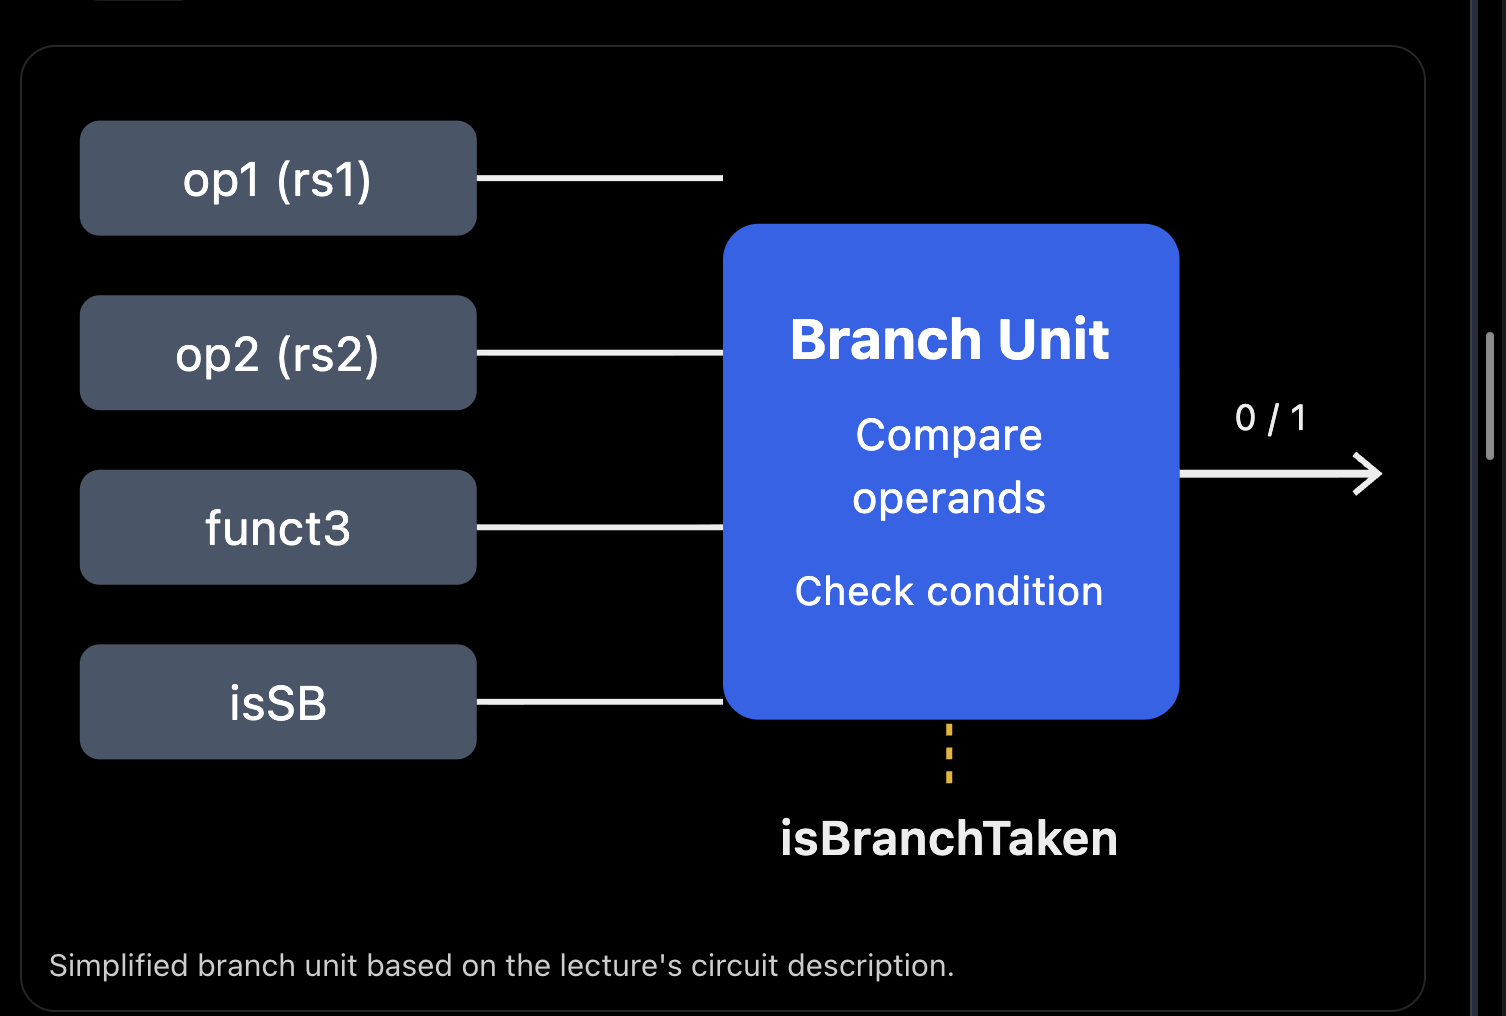
## 3. How does the comparator decide?

There are two main cases.

### Case 1: Instruction is not a branch

```
add x1, x2, x3
```

Here, `isSB = 0`.

The branch unit produces:

$$\boxed{isBranchTaken = 0}$$

No conditional branch is being executed.

### Case 2: Instruction is a conditional branch

```
beq x1, x2, target
```

Here, `isSB = 1`.

Now the comparator checks the relevant condition.

For `beq`:

$$
isBranchTaken =
\begin{cases}
1 & \text{if } op1 = op2 \\
0 & \text{otherwise}
\end{cases}
$$

The `funct3` field tells the branch unit which comparison to perform.

---

## 4. What does `funct3` specify?

RISC-V supports several conditional branch instructions.

| Instruction | `funct3` | Condition |
|-------------|----------|-----------|
| `beq` | `000` | Equal |
| `bne` | `001` | Not equal |
| `blt` | `100` | Less than (signed) |
| `bge` | `101` | Greater than or equal (signed) |
| `bltu` | `110` | Less than (unsigned) |
| `bgeu` | `111` | Greater than or equal (unsigned) |

For instance:

```
bne x1, x2, target
```

If:

$$x1 = 10, \qquad x2 = 20$$

The condition is true because the values are different.

Hence:

$$\boxed{isBranchTaken = 1}$$

The Fetch stage uses the **branch target** instead of `PC + 4`.

---

## 5. How does this connect to the Fetch stage?

Remember our earlier explanation:

- **Decode** calculates the branch target.
- **Execute** determines whether the branch is taken.
- **Fetch** selects the next PC.
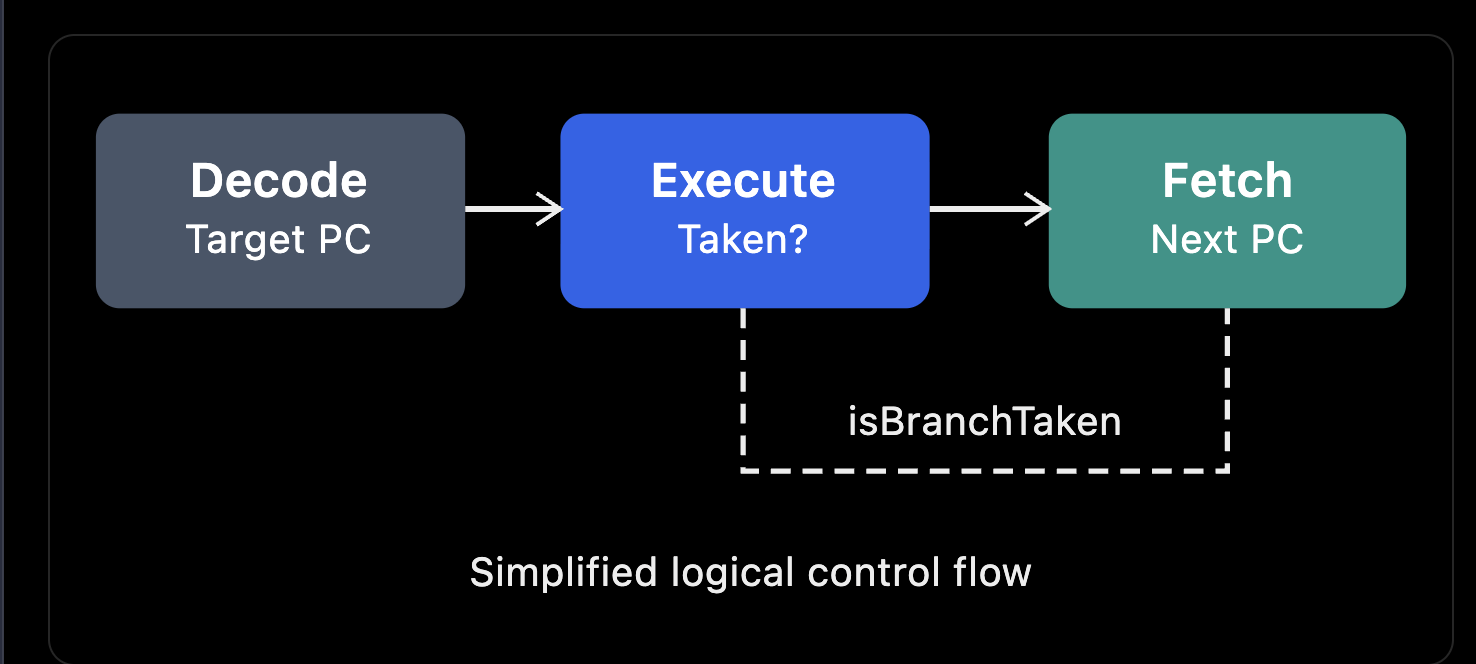
In the professor's design, the Execute stage supplies both the candidate target (through its result-selection path) and `isBranchTaken` to Fetch.

The selected PC is:

$$
PC_{\text{next}} =
\begin{cases}
PC + \text{offset} & isBranchTaken = 1 \\
PC + 4 & isBranchTaken = 0
\end{cases}
$$

> 📌 This formula describes **conditional branches**. Unconditional jumps are handled by additional control logic.

---

## 6. Execute stage summary

We have now completed the entire Execute stage from Lecture 20.

| Component | Function |
|-----------|----------|
| ALU | Performs arithmetic and logical operations |
| Operand MUX | Selects register operand or immediate |
| Result MUXes | Select ALU result, immediate or branch target |
| Branch comparator | Checks branch conditions |
| Control signals | Determine selected operations and data paths |

The two major outputs in your professor's datapath are:

- **`ALUResult`** — the selected execution result, effective address or branch target.
- **`isBranchTaken`** — whether a conditional branch should redirect the PC.


# Lecture 20 — Part 5: Memory Access (MEM)

**Professor's Transcript: 32:40–38:37**

---

## 1. Why Do We Need a Memory Access Stage?

Remember that in RISC-V, the **ALU works primarily with data stored in registers**.

But what if the data is in main memory?

Consider:

```asm
lw x5, 8(x10)
```

This instruction means:

> Read a 32-bit word from memory at address `x10 + 8` and place it in register `x5`.

The processor cannot complete this instruction using only the ALU.

We need a stage that communicates with **Data Memory**.

This is the **Memory Access (MEM) stage**.

### Which Instructions Access Data Memory?

| Instruction Type | Memory Access |
|---|---|
| R-type (`add`, `sub`) | No |
| I-type arithmetic (`addi`) | No |
| Load (`lw`) | Read |
| Store (`sw`) | Write |
| Branch (`beq`) | No |

**Important:** Only LOAD and STORE instructions access data memory in this simplified RISC-V datapath.

Other instructions pass through the MEM stage without performing a data-memory operation.

---

## 2. The Two Important Registers: MAR and MDR

At approximately **35:34**, the professor introduces two registers.

### MAR — Memory Address Register

The **Memory Address Register (MAR)** holds the address of the memory location to be accessed.

### MDR — Memory Data Register

The **Memory Data Register (MDR)** holds the data being transferred between the processor and memory.

### Key Difference

| Register | Full Form | Responsibility |
|---|---|---|
| MAR | Memory Address Register | Stores the memory address |
| MDR | Memory Data Register | Holds the data being transferred |

**Remember:**

- **MAR → WHERE** to access memory.
- **MDR → WHAT** data is transferred.

They have completely different responsibilities.

---

## 3. Memory Access Circuit

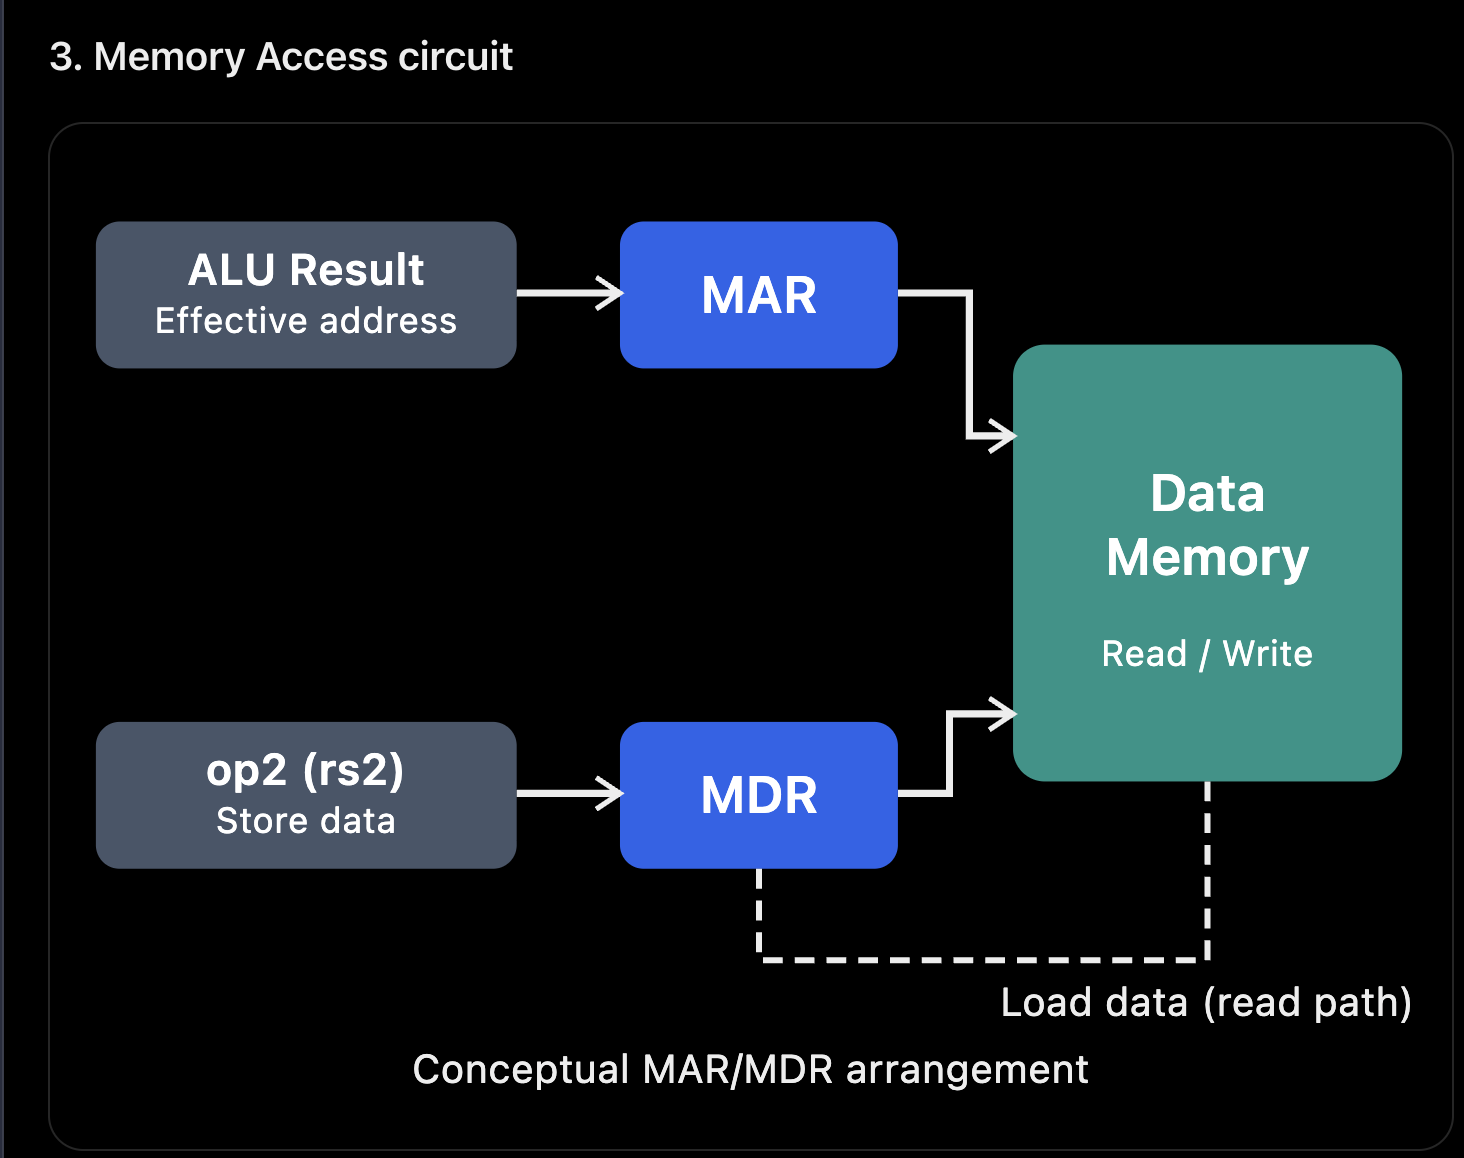

The memory access circuitry uses:

- **Address input:** Effective address calculated by the ALU.
- **Write data input:** Register value to store in memory.
- **Read data output:** Value retrieved from memory.
- **isLoad:** Control signal indicating a load instruction.
- **isStore:** Control signal indicating a store instruction.

### Important Clarification

MAR and MDR are conceptual registers used by the professor to explain memory access.

In a simplified single-cycle RISC-V datapath, these may be represented implicitly through address and data connections rather than dedicated registers.

---

## 4. LOAD Instruction — Step-by-Step

Consider:

```asm
lw x5, 12(x10)
```

Suppose:

$$
x10 = 2000
$$

And:

$$
Memory[2012] = 75
$$

### Step 1: Calculate the Effective Address

During the **Execute (EX) stage**, the ALU calculates:

$$
EA = R[x10] + Immediate
$$

$$
EA = 2000 + 12 = \boxed{2012}
$$

### Step 2: MAR Receives the Address

$$
MAR = 2012
$$

The processor now knows which memory location to access.

### Step 3: Read From Memory

The memory system reads the word at address 2012.

$$
Memory[2012] = 75
$$

### Step 4: MDR Receives the Data

$$
MDR = 75
$$

In the professor's terminology, the memory-stage output is called:

`LoadResult = 75`

### Step 5: Writeback

During the **Writeback (WB) stage**, the loaded value is written into destination register `x5`.

$$
\boxed{x5 = 75}
$$

### Important Distinction

$$
\underbrace{2012}_{\text{Memory Address}}
\neq
\underbrace{75}_{\text{Stored Data}}
$$

**2012 is WHERE the data is stored.**

**75 is WHAT the memory contains.**

---

## 5. STORE Instruction — Step-by-Step

Consider:

```asm
sw x5, 12(x10)
```

Suppose:

$$
x10 = 2000, \qquad x5 = 75
$$

Unlike `lw`, the processor is not retrieving data from memory.

It is **writing data into memory**.

### Step 1: Calculate the Effective Address

During Execute:

$$
EA = R[x10] + Immediate
$$

$$
EA = 2000 + 12 = \boxed{2012}
$$

### Step 2: MAR Receives the Address

$$
MAR = 2012
$$

### Step 3: MDR Receives the Data

The data to be stored comes from register `x5`.

$$
MDR = R[x5] = 75
$$

### Step 4: Write Into Memory

The processor stores the value at the calculated address.

$$
\boxed{Memory[2012] = 75}
$$

### Important Observation

STORE instructions **do not perform register writeback**.

Why?

Because the destination is **memory**, not a register.

---

## 6. LOAD vs STORE — Exam Comparison

| Feature | LOAD (`lw`) | STORE (`sw`) |
|---|---|---|
| Direction | Memory → Register | Register → Memory |
| Address Calculation | `rs1 + immediate` | `rs1 + immediate` |
| MAR | Holds effective address | Holds effective address |
| Data Transfer | Reads from memory | Writes to memory |
| Register Writeback | Yes | No |
| Main Control Signal | `isLoad` | `isStore` |
| Instruction Format | I-type | S-type |

### Control Signals

The Memory Access stage receives two important signals from the control unit.

**isLoad**

- `isLoad = 1` → Perform a memory read.

**isStore**

- `isStore = 1` → Perform a memory write.

**Neither Signal Active**

- `isLoad = 0`
- `isStore = 0`

No data-memory access is performed.

### Final Revision

**LOAD:**

$$
\boxed{Register \leftarrow Memory[Base + Offset]}
$$

**STORE:**

$$
\boxed{Memory[Base + Offset] \leftarrow Register}
$$

**Remember:**

- **EX stage:** Calculates the effective address.
- **MEM stage:** Reads or writes memory.
- **WB stage:** Writes a result into the register file when required.

---


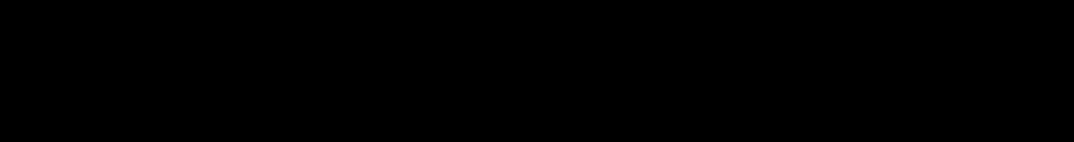


# Lecture 20 — Part 6: Register Writeback (WB)

**Professor's Transcript: 38:37–42:47**

---

## 1. Why Do We Need Writeback?

Consider:

```asm
add x5, x6, x7
```

Suppose:

$$
x6 = 10, \qquad x7 = 20
$$

During the **Execute (EX) stage**, the ALU calculates:

$$
10 + 20 = 30
$$

But here's the problem:

**Calculating 30 doesn't automatically update register `x5`.**

The processor must explicitly write the result into the destination register.

That is the purpose of the **Writeback stage (WB)**.

$$
\boxed{\text{Writeback} = \text{Writing the final result into } rd}
$$

However, different instructions produce their final results in different places.

---

## 2. Where Does the Final Result Come From?

Let's examine three instructions.

### Case 1 — Arithmetic: ALU Result

```asm
add x5, x6, x7
```

If `x6 = 10` and `x7 = 20`, then:

$$
ALUResult = 30 \Rightarrow x5 = 30
$$

**The final value comes from the Execute stage.**

### Case 2 — Load: Load Result

```asm
lw x5, 8(x10)
```

If `x10 = 1000` and `Memory[1008] = 75`:

$$
LoadResult = 75 \Rightarrow x5 = 75
$$

**The final value comes from the Memory Access stage.**

### Case 3 — Jump and Link: PC + 4

```asm
jal x1, target
```

Suppose the current PC is `2000`.

$$
PC + 4 = 2004 \Rightarrow x1 = 2004
$$

The jump changes the PC to the target address, while `x1` receives the **return address**.

> 💡 Notice something:
>
> The processor must write a value into a destination register, but the source of that value varies according to the instruction.

**How do we solve this using hardware?**

Exactly the same technique we've used throughout the datapath: a **multiplexer (MUX)**.

---

## 3. Writeback Multiplexer Circuit

At approximately **40:31–41:55**, the professor introduces a MUX with three inputs:

- **ALU Result**
- **Load Result**
- **PC + 4**

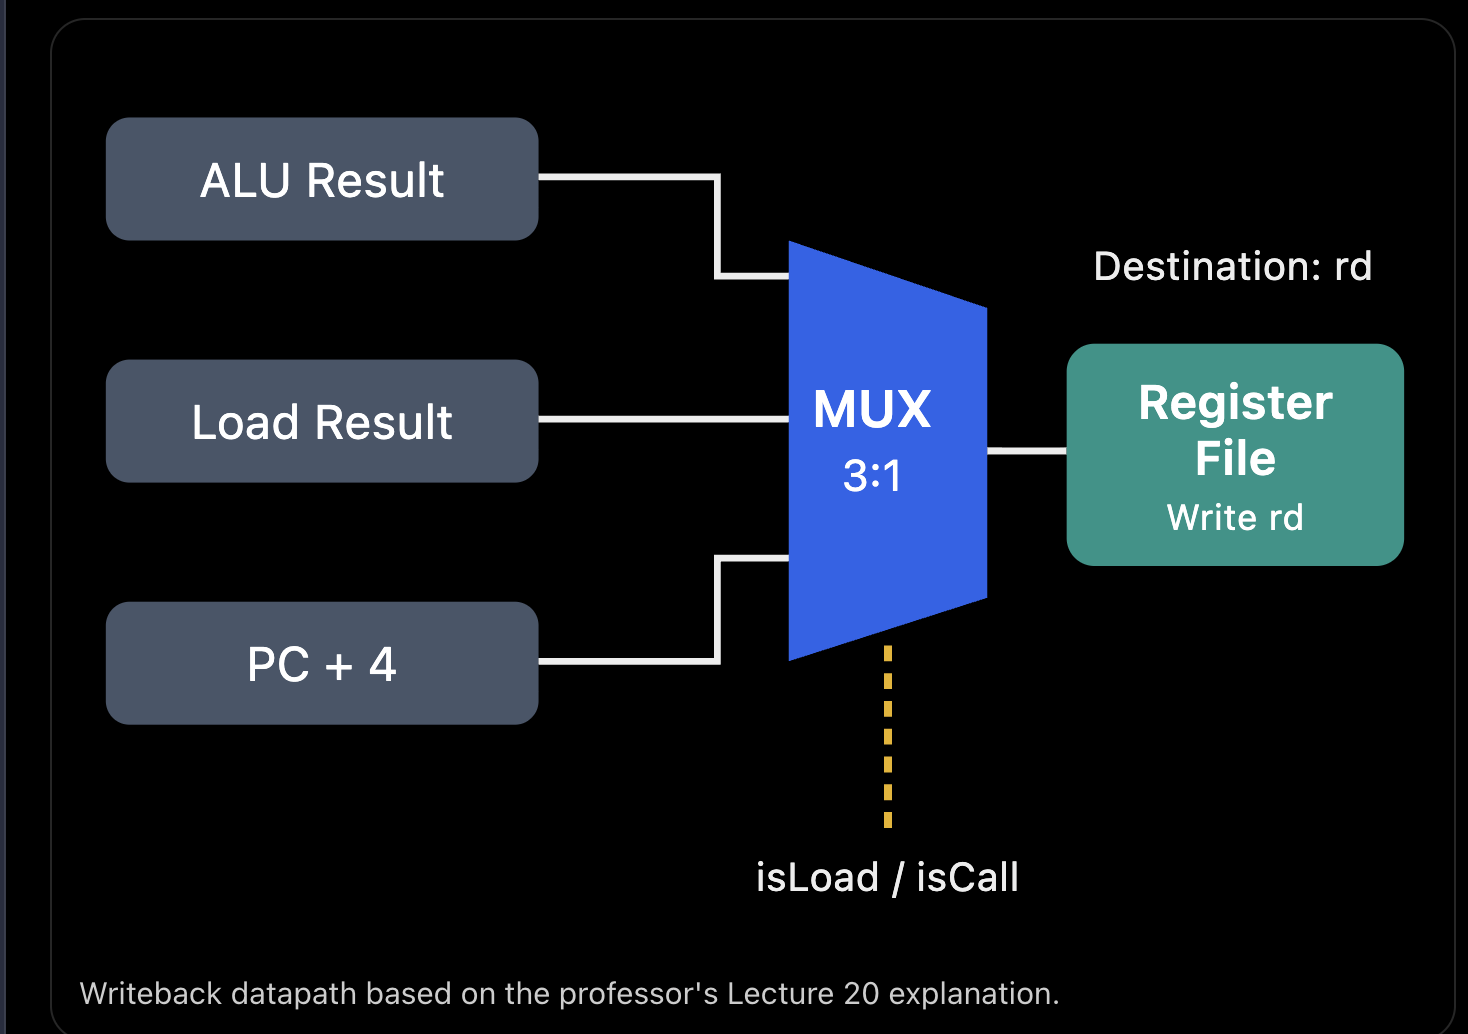

*Writeback datapath based on the professor's Lecture 20 explanation.*

### How Does This Circuit Work?

The multiplexer receives all three possible values.

The control unit decides which one is written into the register file.

The professor uses two signals:

- `isLoad`
- `isCall`

### MUX Selection Table

| `isLoad` | `isCall` | Selected Result |
|---|---|---|
| 0 | 0 | ALU Result |
| 1 | 0 | Load Result |
| 0 | 1 | PC + 4 |
| 1 | 1 | Not used in this design |

Here, `isCall` is the professor's signal for **jump-and-link instructions** that save a return address, such as `jal` and `jalr`.

### Example: LOAD Instruction

```asm
lw x5, 8(x10)
```

Since this is a load instruction:

$$
isLoad = 1, \qquad isCall = 0
$$

The MUX selects **Load Result**, not ALU Result.

**Why?**

Because for a load instruction:

- **ALU Result** = Memory address.
- **Load Result** = Actual data retrieved from memory.

Writing the ALU Result would incorrectly put the address into `x5`.

This is precisely the distinction we corrected in Understanding Check 4.

---

## 4. What Is the Role of `rd`?

The register file needs two things to perform writeback:

1. **Which register should be updated?** → `rd`
2. **What value should be written?** → MUX output

For example:

```asm
add x5, x6, x7
```

Here:

- `rd = x5`
- Write data = ALU Result

The register file writes the ALU result into `x5`.

### Register Write Enable — `RegWrite`

There's one additional control signal called **RegWrite** (often represented as `RegWrite` or `RegisterWriteEnable`).

| Instruction | RegWrite |
|---|---|
| `add` | 1 |
| `addi` | 1 |
| `lw` | 1 |
| `lui` | 1 |
| `jal` | 1 |
| `sw` | 0 |
| `beq` | 0 |

### Why Is This Necessary?

Because not every instruction writes into a register.

For example:

```asm
sw x5, 8(x10)
```

This stores data in memory. It does **not** write into any destination register.

Therefore:

$$
RegWrite = 0
$$

The professor focuses on the result-selection MUX, but the register write-enable signal is essential for a functioning datapath.

---

## 5. Entire Datapath — One Final Overview

We've now finished the material up to approximately **42:47**.

The remainder of Lecture 20 summarizes the five stages.

### Exam-Ready Stage Summary

| Stage | Full Name | Main Function |
|---|---|---|
| IF | Instruction Fetch | Fetch instruction and calculate sequential PC |
| ID | Instruction Decode | Decode instruction, read registers, generate immediate and branch target |
| EX | Execute | ALU operations, effective address calculation, branch decision |
| MEM | Memory Access | Read/write data memory for load/store |
| WB | Writeback | Write the selected result into the destination register |

---

**That completes the professor's Lecture 20.**
